In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

In [2]:
data = np.load("/media/ian/Poppy/improved-nn/qle-v3/634e14bc75836df75158fb15f379d8bb/dataset_init.npz")
data2 = np.load("/media/ian/Poppy/improved-nn/qle-v3/634e14bc75836df75158fb15f379d8bb/dataset_init_f64.npz")

dataesl = np.load("/media/ian/Poppy/improved-nn/qle-v3/09d3dccc56f1fa9330b57901cd232ab7/dataset_init.npz")
dataesl2 = np.load("/media/ian/Poppy/improved-nn/qle-v3/09d3dccc56f1fa9330b57901cd232ab7/dataset_init_f64.npz")

In [3]:
list(data.keys())

['pos', 'box', 'evals', 'orig_evecs', 'evecs']

In [4]:
data["box"]

array([165.24728394, 165.24728394,   0.        ,   0.        ,
         0.        ,   0.        ])

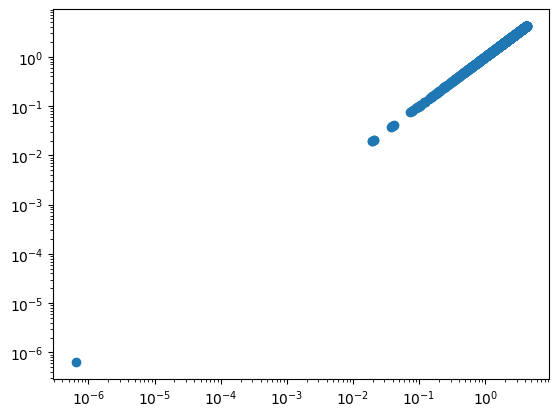

In [42]:
plt.plot(data["evals"], data["evals"], "o")
plt.yscale('log')
plt.xscale('log')

In [109]:
evecs = data["evecs"]
evals = data["evals"]

evecs_esl = dataesl["evecs"]
evals_esl = dataesl["evals"]

In [143]:
def get_anharm_mag(evals, evecs):
    out = []
    for i in range(len(evals)):
        if evals[i] < 1e-4:
            continue
        term = np.linalg.norm(evecs[i])**2/evals[i]**2
        out.append(term)
        # if term > 300:
        #     print(i)
    return out

83
103


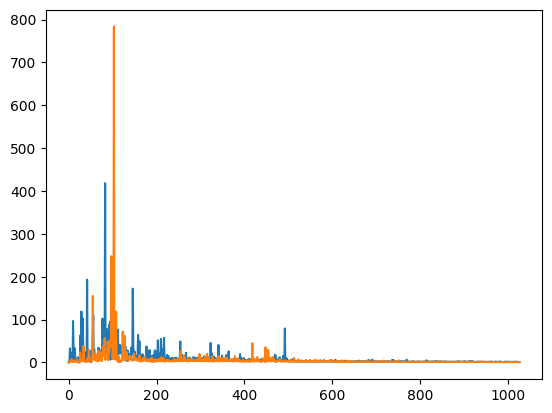

In [111]:
out = get_anharm_mag(evals, evecs)
out_esl = get_anharm_mag(evals_esl, evecs_esl)

plt.plot(out)
plt.plot(out_esl)

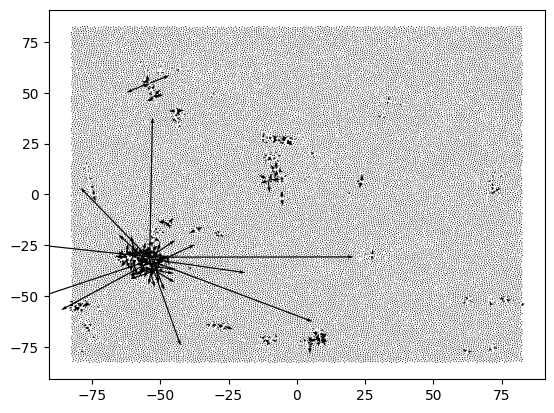

In [135]:
#make arrow plot from evecs and pos
evecs = data2["evecs"][10]/data2["evals"][10]
pos = data2["pos"]

plt.figure()
plt.quiver(pos[:,0], pos[:,1], evecs[:,0], evecs[:,1], scale=10)

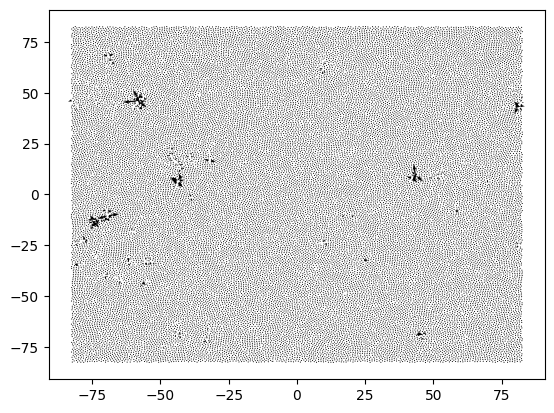

In [136]:
#make arrow plot from evecs and pos
evecs_esl = dataesl2["evecs"][10]/dataesl2["evals"][10]
pos_esl = dataesl2["pos"]

plt.figure()
plt.quiver(pos_esl[:,0], pos_esl[:,1], evecs_esl[:,0], evecs_esl[:,1], scale=10)

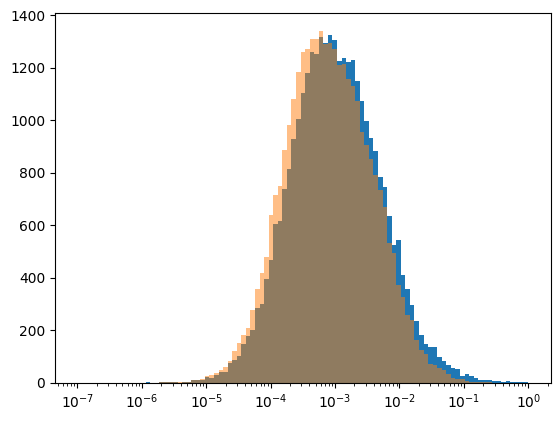

In [137]:
plt.hist(np.linalg.norm(evecs, axis=1), bins=np.geomspace(1e-7, 1e0, 100))
plt.hist(np.linalg.norm(evecs_esl, axis=1), bins=np.geomspace(1e-7, 1e0, 100), alpha=0.5)
plt.xscale('log')


In [35]:
evecs.dtype

dtype('float32')

In [36]:
evecs2 = data2["evecs"][100]

In [37]:
pearsonr(evecs.flatten(), evecs2.flatten())

PearsonRResult(statistic=0.9999999773591306, pvalue=0.0)

In [144]:
def get_ipr(evals, evecs):
    iprs = []
    for i in range(len(evals)):
        if evals[i] < 1e-4:
            continue
        norm = np.linalg.norm(evecs[i], axis=-1)
        ipr = np.sum(norm**4)/np.sum(norm**2)**2
        iprs.append(ipr)
    return iprs

In [151]:
import seaborn as sns

/tmp/ipykernel_719956/3997606402.py:15: UserWarning: 

`shade_lowest` has been replaced by `thresh`; setting `thresh=0.05.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(x=np.log(out), y=np.log(iprs), cmap="Blues", shade=True, shade_lowest=False, alpha=0.8)
/tmp/ipykernel_719956/3997606402.py:15: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(x=np.log(out), y=np.log(iprs), cmap="Blues", shade=True, shade_lowest=False, alpha=0.8)
/tmp/ipykernel_719956/3997606402.py:16: UserWarning: 

`shade_lowest` has been replaced by `thresh`; setting `thresh=0.05.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(x=np.log(out_esl), y=np.log(iprs_esl), cmap="Reds", shade=True, shade_lowest=False, alpha=0.8)
/tmp/ipykernel_719956/3997606402.py:16: FutureWarning: 

`shade` is now deprecated in favor of `fill`

<Axes: >

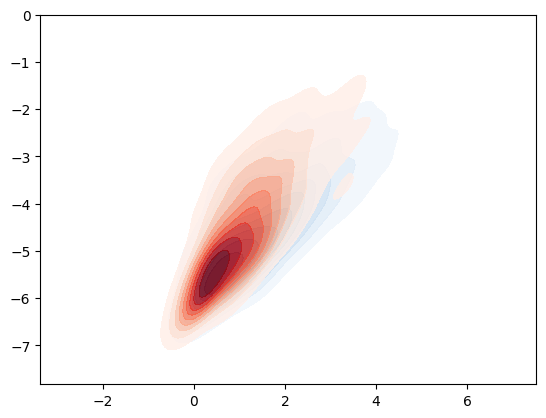

In [155]:
evals = data["evals"]
evecs = data["evecs"]
evals_esl = dataesl["evals"]
evecs_esl = dataesl["evecs"]

iprs = get_ipr(evals, evecs)
iprs_esl = get_ipr(evals_esl, evecs_esl)

out = get_anharm_mag(evals, evecs)
out_esl = get_anharm_mag(evals_esl, evecs_esl)

# plt.hist2d(np.log(out), np.log(iprs), bins=50);
# plt.figure()
# plt.hist2d(np.log(out_esl), np.log(iprs_esl), bins=50);
sns.kdeplot(x=np.log(out), y=np.log(iprs), cmap="Blues", shade=True, shade_lowest=False, alpha=0.8)
sns.kdeplot(x=np.log(out_esl), y=np.log(iprs_esl), cmap="Reds", shade=True, shade_lowest=False, alpha=0.8)